# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('../data/global_energy_mix.csv')

source_category = {
    'Coal': 'Fossil',
    'Oil': 'Fossil',
    'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon',
    'Hydro': 'Low-carbon',
    'Wind': 'Renewable',
    'Solar': 'Renewable',
    'Other Renewables': 'Renewable'
}

df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))

Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


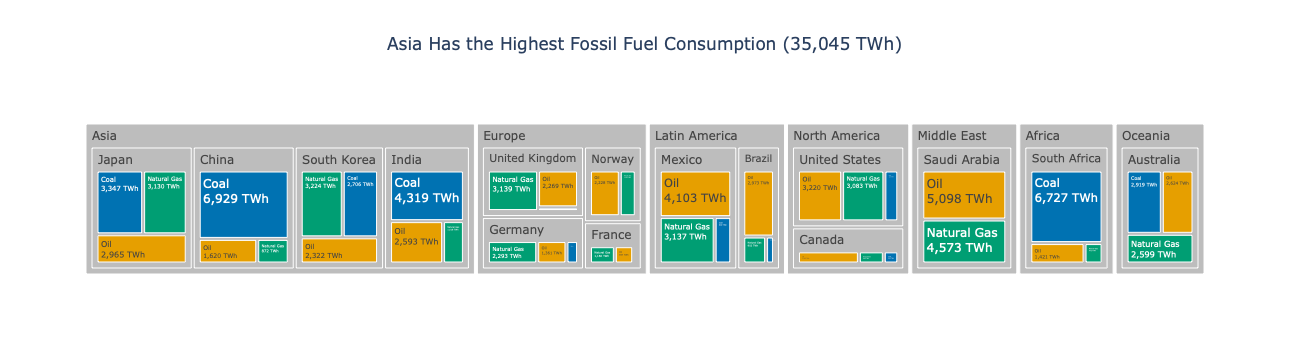

Fossil fuel data: 43 rows
Highest fossil fuel consumption: Asia
Total fossil fuel consumption: 35045.1 TWh


In [2]:

# Task 1 — Fossil Fuel Treemap

# 1. Filter fossil fuels only
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# 2. Find the region with the highest fossil fuel consumption
region_totals = (
    df_fossil.groupby('Region')['TWh']
    .sum()
    .sort_values(ascending=False)
)

top_region = region_totals.index[0]
top_twh = region_totals.iloc[0]

# 3. CVD-safe colour palette
fossil_colors = {
    'Coal': '#0072B2',
    'Oil': '#E69F00',
    'Natural Gas': '#009E73'
}

# 4. Create hierarchical treemap
fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    title=(
        f'{top_region} Has the Highest Fossil Fuel Consumption '
        f'({top_twh:,.0f} TWh)'
    )
)

# 5. Grey out parent nodes (Region and Country)
node_colors = [
    fossil_colors.get(node.split('/')[-1], '#BDBDBD')
    if node.count('/') == 2 else '#BDBDBD'
    for node in fig1.data[0].ids
]

fig1.update_traces(
    marker=dict(colors=node_colors),
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    textinfo='label+value',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>'
)

fig1.update_layout(
    template='plotly_white',
    title_x=0.5
)

fig1.show()

print("Fossil fuel data:", len(df_fossil), "rows")
print("Highest fossil fuel consumption:", top_region)
print("Total fossil fuel consumption:", round(top_twh, 2), "TWh")



## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

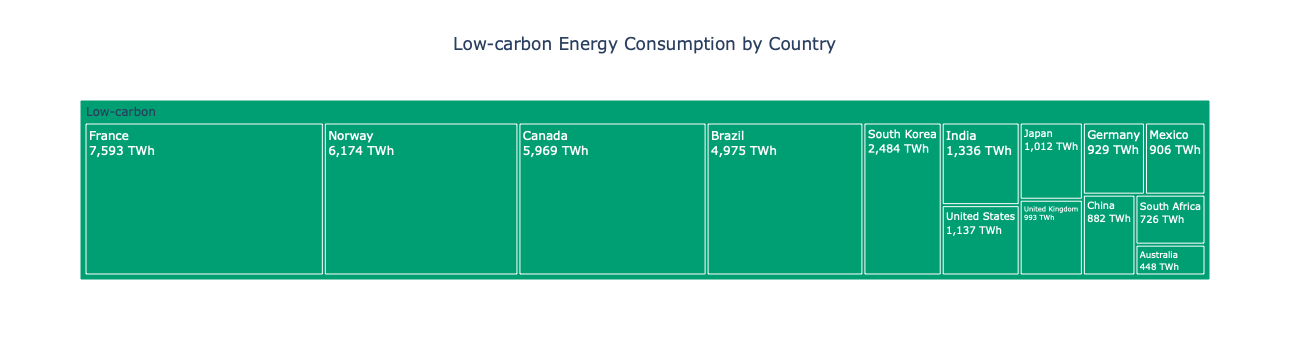

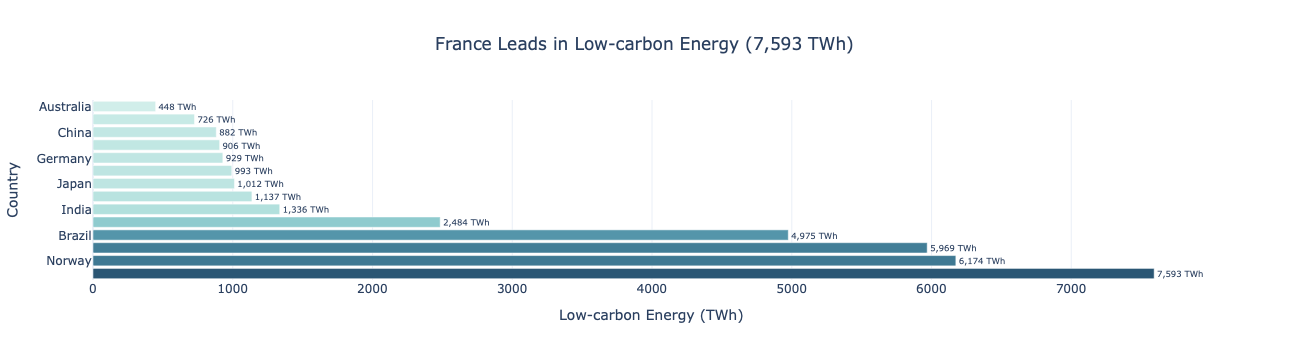

Leading country: France
Low-carbon energy: 7593.0 TWh


In [3]:

# Task 2 — Low-carbon Energy by Country

# 1. Filter low-carbon energy sources
df_low = df.loc[
    df['Source_Type'] == 'Low-carbon'
].copy()

# 2. Aggregate TWh by country
country_totals = (
    df_low.groupby('Country', as_index=False)['TWh']
    .sum()
    .sort_values('TWh', ascending=False)
)

# 3. Add dummy root column for treemap
country_totals['All'] = 'Low-carbon'

# 4. Find leading country
top_country = country_totals.iloc[0]['Country']
top_country_twh = country_totals.iloc[0]['TWh']

# 5. Treemap
fig2 = px.treemap(
    country_totals,
    path=['All', 'Country'],
    values='TWh',
    color='All',
    color_discrete_map={'Low-carbon': '#009E73'},
    title='Low-carbon Energy Consumption by Country'
)

fig2.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>'
)

fig2.update_layout(
    template='plotly_white',
    title_x=0.5
)

fig2.show()


# 6. Horizontal bar chart
fig3 = px.bar(
    country_totals.sort_values('TWh', ascending=True),
    x='TWh',
    y='Country',
    orientation='h',
    text='TWh',
    color='TWh',
    color_continuous_scale='Teal',
    title=(
        f'{top_country} Leads in Low-carbon Energy '
        f'({top_country_twh:,.0f} TWh)'
    ),
    labels={
        'TWh': 'Low-carbon Energy (TWh)',
        'Country': 'Country'
    }
)

fig3.update_traces(
    texttemplate='%{x:,.0f} TWh',
    textposition='outside'
)

fig3.update_layout(
    template='plotly_white',
    title_x=0.5,
    coloraxis_showscale=False,
    yaxis=dict(autorange='reversed')
)

fig3.show()

print("Leading country:", top_country)
print("Low-carbon energy:", round(top_country_twh, 2), "TWh")


### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE* The horizontal bar chart tells the ranking story more clearly because all countries share the same baseline, making it easier to compare their TWh values and identify the highest and lowest countries.

The treemap is useful for understanding the part-to-whole relationship and comparing the relative contribution of each country to the total low-carbon energy consumption.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

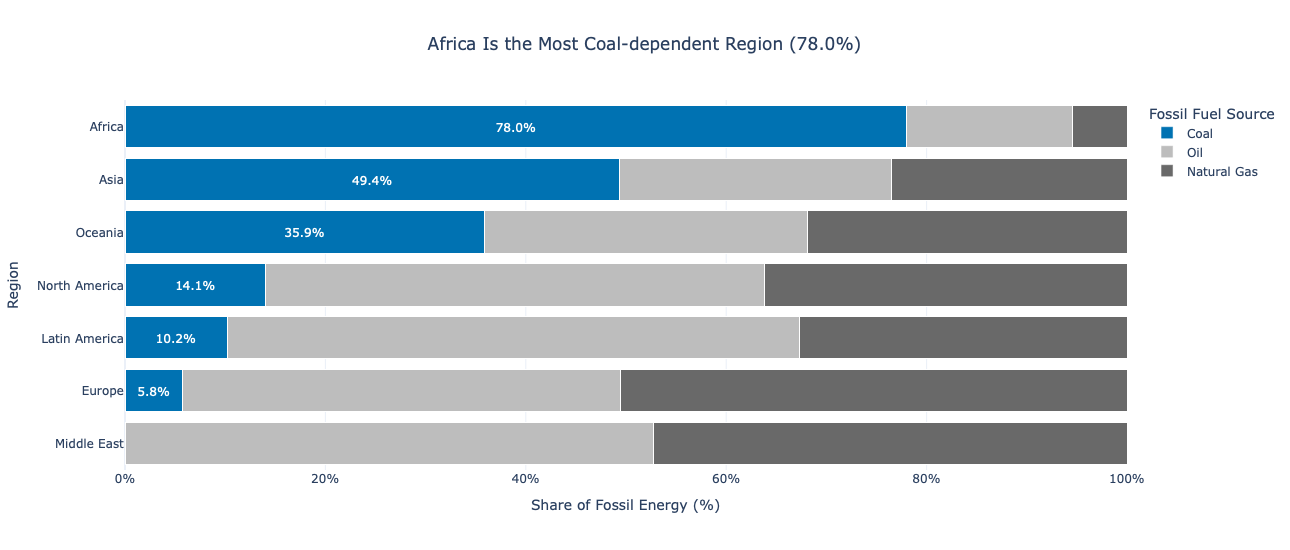

Most coal-dependent region: Africa
Coal share: 78.04 %


In [4]:

# Task 3 — 100% Stacked Bar Chart

# 1. Aggregate TWh by Region and Source
df_region = (
    df_fossil.groupby(
        ['Region', 'Source'],
        as_index=False
    )['TWh'].sum()
)

# 2. Calculate each region's total fossil energy
df_region['Region_Total'] = (
    df_region.groupby('Region')['TWh'].transform('sum')
)

# 3. Calculate percentage share
df_region['Share_pct'] = (
    df_region['TWh'] / df_region['Region_Total'] * 100
)

# 4. Calculate coal share for each region
coal_shares = (
    df_region[df_region['Source'] == 'Coal']
    .set_index('Region')['Share_pct']
)

# 5. Find the most coal-dependent region
top_coal_region = coal_shares.idxmax()
top_coal_share = coal_shares.max()

# 6. Sort regions by coal share
region_order = (
    coal_shares.sort_values(ascending=True).index.tolist()
)

# 7. Add labels only to Coal segments
df_region['Coal_Label'] = np.where(
    df_region['Source'] == 'Coal',
    df_region['Share_pct'].map(lambda x: f'{x:.1f}%'),
    ''
)

# 8. Colours: Coal blue, Oil and Natural Gas grey
source_colors = {
    'Coal': '#0072B2',
    'Oil': '#BDBDBD',
    'Natural Gas': '#696969'
}

# 9. Create horizontal 100% stacked bar chart
fig4 = px.bar(
    df_region,
    x='Share_pct',
    y='Region',
    color='Source',
    orientation='h',
    barmode='stack',
    text='Coal_Label',
    color_discrete_map=source_colors,
    category_orders={
        'Source': ['Coal', 'Oil', 'Natural Gas'],
        'Region': region_order
    },
    title=(
        f'{top_coal_region} Is the Most Coal-dependent Region '
        f'({top_coal_share:.1f}%)'
    ),
    labels={
        'Share_pct': 'Share of Fossil Energy (%)',
        'Region': 'Region',
        'Source': 'Energy Source'
    }
)

fig4.update_traces(
    textposition='inside',
    insidetextanchor='middle'
)

fig4.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis=dict(
        range=[0, 100],
        ticksuffix='%',
        title='Share of Fossil Energy (%)'
    ),
    yaxis=dict(
        autorange='reversed',
        title='Region'
    ),
    legend_title='Fossil Fuel Source',
    height=550
)

fig4.show()

print("Most coal-dependent region:", top_coal_region)
print("Coal share:", round(top_coal_share, 2), "%")


### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*